# 12 — Filtros y normalización

**Objetivo:** medir si filtrar la señal o normalizar el volumen mejora la
clasificación, sobre la extracción corregida de la notebook 11. Es la
pregunta central de tu directora: "importa más el preprocesamiento que la
clasificación". Al terminar deberías poder:
- explicar los tres filtros candidatos y por qué se fijaron de antemano;
- decir si algún filtro mejora la clasificación, y en qué subconjunto;
- explicar por qué el pasa banda "clínico" de 25–400 Hz **empeora** la
  clasificación cardíaca;
- leer una curva de sensibilidad (el AUC según el corte del pasa bajo) sin
  usarla para elegir el corte;
- decir si el resultado pulmonar depende del volumen de la grabación.

Las reglas son las de la notebook 11: los cuatro modelos con `class_weight`,
validación cruzada estratificada de 5 particiones repetida 3 veces, umbral
0,5, y cada versión se compara con la línea de base (sin filtro, sin
normalizar) con el **bootstrap pareado**.

*(La notebook tarda unos 15 minutos en correr entera; el bootstrap de la
sección 3 es lo más lento.)*

In [1]:
import sys
import time
import warnings
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import signal
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.svm import SVC
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.evaluation import make_pipeline
from src.features import load_metadata
from src.paths import AUDIO, OUT_DIR

warnings.filterwarnings("ignore")

SR = 4000        # frecuencia nativa (notebook 11)
F_TONO = 146     # el tono del equipo (notebook 02)
NO_FEATURES = ["file_id", "label", "label_binary"]
SEMILLA = 0
REPETICIONES = 3
NOMBRE = {"LS": "Pulmonares", "HS": "Cardíacos"}
MODELOS = ["Regresión logística", "SVM-RBF", "Random forest", "XGBoost"]

AZUL, NARANJA, AQUA, AMARILLO, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6})


def extraer(y, sr=SR, n_fft=372, salto=93, bandas_contraste=4, centrar=False):
    """La extracción corregida de la notebook 11 (4000 Hz, tramas de 93 ms, sin relleno)."""
    tramas = dict(n_fft=n_fft, hop_length=salto, center=centrar)
    f = {}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, **tramas)
    for i, c in enumerate(mfcc, 1):
        f[f"mfcc_{i}_mean"], f[f"mfcc_{i}_std"] = c.mean(), c.std()
        f[f"mfcc_{i}_max"], f[f"mfcc_{i}_min"] = c.max(), c.min()
    delta = librosa.feature.delta(mfcc, width=9)
    for i, c in enumerate(delta, 1):
        f[f"mfcc_delta_{i}_mean"], f[f"mfcc_delta_{i}_std"] = c.mean(), c.std()
    for nombre, funcion in [("spectral_centroid", librosa.feature.spectral_centroid),
                            ("spectral_bandwidth", librosa.feature.spectral_bandwidth),
                            ("spectral_rolloff", librosa.feature.spectral_rolloff)]:
        s = funcion(y=y, sr=sr, **tramas)[0]
        f[f"{nombre}_mean"], f[f"{nombre}_std"] = s.mean(), s.std()
    contraste = librosa.feature.spectral_contrast(y=y, sr=sr, n_bands=bandas_contraste, **tramas)
    for i, c in enumerate(contraste, 1):
        f[f"spectral_contrast_{i}_mean"], f[f"spectral_contrast_{i}_std"] = c.mean(), c.std()
    s = librosa.feature.spectral_flatness(y=y, **tramas)[0]
    f["spectral_flatness_mean"], f["spectral_flatness_std"] = s.mean(), s.std()
    s = librosa.feature.zero_crossing_rate(y, frame_length=n_fft, hop_length=salto, center=centrar)[0]
    f["zcr_mean"], f["zcr_std"] = s.mean(), s.std()
    s = librosa.feature.rms(y=y, frame_length=n_fft, hop_length=salto, center=centrar)[0]
    f["rms_mean"], f["rms_std"], f["rms_max"] = s.mean(), s.std(), s.max()
    return {k: (v if np.isfinite(v) else 0.0) for k, v in f.items()}


def modelos(y):
    """Los cuatro modelos de las notebooks 10 y 11."""
    peso_xgb = (y == 0).sum() / (y == 1).sum()
    return {
        "Regresión logística": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"),
                                             "class_weight"),
        "SVM-RBF": make_pipeline(SVC(kernel="rbf", class_weight="balanced"), "class_weight"),
        "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                              random_state=SEMILLA), "class_weight"),
        "XGBoost": make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                               scale_pos_weight=peso_xgb, eval_metric="logloss",
                                               random_state=SEMILLA, n_jobs=1), "class_weight"),
    }


def puntajes(modelo, X, y, cv, grupos=None):
    if hasattr(modelo, "predict_proba"):
        return cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return 1 / (1 + np.exp(-cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="decision_function")))


def prob_validacion(modelo, X, y):
    return [puntajes(modelo, X, y, StratifiedKFold(5, shuffle=True, random_state=s)) for s in range(REPETICIONES)]


def auc_medio(y, probs):
    return np.mean([roc_auc_score(y, p) for p in probs])


def metricas(y, probs, umbral=0.5):
    filas = []
    for p in probs:
        tn, fp, fn, tp = confusion_matrix(y, p >= umbral, labels=[0, 1]).ravel()
        sens, esp = tp / (tp + fn), tn / (tn + fp)
        filas.append({"AUC": roc_auc_score(y, p), "sens.": sens, "esp.": esp, "exact. bal.": (sens + esp) / 2})
    return pd.DataFrame(filas).mean()


def dif_pareada(y, p_nueva, p_vieja, n=1000):
    """Diferencia de AUC (nueva − vieja) e IC 95 % por bootstrap pareado (notebook 11)."""
    rng = np.random.default_rng(SEMILLA)
    valores = []
    while len(valores) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            valores.append(auc_medio(y[m], [p[m] for p in p_nueva]) - auc_medio(y[m], [p[m] for p in p_vieja]))
    return auc_medio(y, p_nueva) - auc_medio(y, p_vieja), np.percentile(valores, [2.5, 97.5])

## 1. Los candidatos, fijados de antemano

Los definimos en la notebook 02, **antes** de mirar ningún resultado, con
argumentos de la señal y clínicos:

| Candidato | Cardíacos | Pulmonares | Por qué |
|---|---|---|---|
| **Sin filtro** | — | — | la línea de base (notebook 11) |
| **Limpieza mínima** | pasa banda 20–1000 Hz + notch 146 Hz | igual | saca solo lo no fisiológico: el retumbo muy grave, el siseo del equipo por encima de ~1100 Hz y su tono de 146 Hz |
| **Banda clínica** | pasa banda 25–400 Hz + notch | pasa banda 100–1000 Hz + notch | cardíacos: la banda del método de segmentación de Springer, Tarassenko y Clifford (2016), la referencia del desafío PhysioNet/CinC 2016. Pulmonares: atenúa el sonido cardíaco y el retumbo, y el siseo |

Sobre el corte de 100 Hz en pulmonares: es una decisión nuestra, apoyada en
la notebook 02 (debajo de ~100–150 Hz domina el sonido cardíaco) y en que el
modo diafragma del estetoscopio ya atenúa por debajo de 200 Hz (Torabi et
al., 2025). Las guías europeas de análisis de sonidos respiratorios (CORSA)
usan cortes más bajos, del orden de 60 Hz, al **registrar**.

Cada candidato se prueba **con y sin normalización** de volumen. Normalizamos
por RMS (la energía media de toda la grabación = 1) y no por el pico, porque
el pico depende de una sola muestra (un roce, un golpe), y el RMS, de toda la
grabación (notebook 02).

**¿Por qué de antemano?** Si probáramos muchos filtros y nos quedáramos con
el que mejor da, estaríamos ajustando el preprocesamiento a las mismas
grabaciones con las que evaluamos (una forma de fuga), y alguno ganaría por
azar. Con pocos candidatos fijados antes, la comparación es honesta.

El orden de cada paso es el de la notebook 02: notch → pasa banda (los dos con
fase cero, sin correr la señal en el tiempo) → normalización → extracción.

In [2]:
def rms(y):
    return np.sqrt(np.mean(y ** 2))


def preprocesar(y, banda=None, notch=False, normalizar=False, pasa_bajo=None):
    """Notch en 146 Hz, pasa banda o pasa bajo (Butterworth de orden 4, fase cero) y normalización RMS."""
    if notch:
        b, a = signal.iirnotch(F_TONO, 30, fs=SR)
        y = signal.filtfilt(b, a, y)
    if banda is not None:
        y = signal.sosfiltfilt(signal.butter(4, banda, btype="bandpass", fs=SR, output="sos"), y)
    if pasa_bajo is not None:
        y = signal.sosfiltfilt(signal.butter(4, pasa_bajo, btype="lowpass", fs=SR, output="sos"), y)
    if normalizar:
        y = y / rms(y)
    return y


BANDA_CLINICA = {"HS": (25, 400), "LS": (100, 1000)}
BASE = "sin filtro"


def candidatos(subset):
    filtros = {"sin filtro": {},
               "limpieza mínima": dict(banda=(20, 1000), notch=True),
               "banda clínica": dict(banda=BANDA_CLINICA[subset], notch=True)}
    versiones = {}
    for nombre, parametros in filtros.items():
        versiones[nombre] = parametros
        versiones[f"{nombre} + RMS"] = {**parametros, "normalizar": True}
    return versiones

## 2. Extraer las seis versiones

Tres filtros por dos normalizaciones, en cada subconjunto. Verificamos además
que la versión sin filtro sea la línea de base guardada en la notebook 11.
*(Tarda alrededor de un minuto.)*

In [3]:
hs_meta, ls_meta = load_metadata()
META = {"LS": (ls_meta, "Lung Sound ID", "Lung Sound Type"),
        "HS": (hs_meta, "Heart Sound ID", "Heart Sound Type")}

inicio = time.time()
audios, tablas = {}, {}
for subset, (meta, col_id, col_tipo) in META.items():
    audios[subset] = {fid: librosa.load(AUDIO[subset] / f"{fid}.wav", sr=SR)[0] for fid in meta[col_id]}
    for version, parametros in candidatos(subset).items():
        filas = [{**extraer(preprocesar(audios[subset][fila[col_id]], **parametros)), "file_id": fila[col_id],
                  "label": fila[col_tipo], "label_binary": int(fila["binary_label"])}
                 for _, fila in meta.iterrows()]
        tablas[(subset, version)] = pd.DataFrame(filas)
    base = pd.read_csv(OUT_DIR / f"{subset.lower()}_features_corregidas.csv")
    # librosa calcula en precisión simple (~7 cifras): según la máquina puede haber diferencias de redondeo
    igual = np.allclose(base.drop(columns=NO_FEATURES), tablas[(subset, BASE)].drop(columns=NO_FEATURES),
                        rtol=1e-4, atol=1e-6)
    print(f"{NOMBRE[subset]}: 6 versiones; la versión sin filtro coincide con la línea de base: {igual}")
print(f"({time.time() - inicio:.0f} segundos)")


def datos(subset, version):
    df = tablas[(subset, version)]
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values
    return df.drop(columns=NO_FEATURES), df["label_binary"].values, caso, df["label"].values

Pulmonares: 6 versiones; la versión sin filtro coincide con la línea de base: True


Cardíacos: 6 versiones; la versión sin filtro coincide con la línea de base: True
(56 segundos)


## 3. ¿Qué cambia en los modelos?

*(Esta celda tarda unos 2 minutos.)*

In [4]:
inicio = time.time()
probs = {}
for subset in META:
    for version in candidatos(subset):
        X, y, caso, tipo = datos(subset, version)
        for nombre, modelo in modelos(y).items():
            probs[(subset, version, nombre)] = prob_validacion(modelo, X, y)
    print(f"{NOMBRE[subset]}: listo")
print(f"({time.time() - inicio:.0f} segundos)")

for subset in META:
    y = datos(subset, BASE)[1]
    resumen = {version: {n: metricas(y, probs[(subset, version, n)]) for n in MODELOS} for version in candidatos(subset)}
    print(f"\n===== {NOMBRE[subset]}: AUC por grabación =====")
    print(pd.DataFrame({v: {n: m["AUC"] for n, m in r.items()} for v, r in resumen.items()}).T.round(3).to_string())
    print(f"\n{NOMBRE[subset]}: especificidad (umbral 0,5)")
    print(pd.DataFrame({v: {n: m["esp."] for n, m in r.items()} for v, r in resumen.items()}).T.round(2).to_string())

Pulmonares: listo


Cardíacos: listo
(169 segundos)



===== Pulmonares: AUC por grabación =====
                       Regresión logística  SVM-RBF  Random forest  XGBoost
sin filtro                           0.999    0.975          0.926    0.868
sin filtro + RMS                     0.999    0.977          0.933    0.874
limpieza mínima                      0.999    0.989          0.947    0.868
limpieza mínima + RMS                1.000    0.985          0.947    0.867
banda clínica                        1.000    0.992          0.970    0.918
banda clínica + RMS                  1.000    0.993          0.987    0.961

Pulmonares: especificidad (umbral 0,5)
                       Regresión logística  SVM-RBF  Random forest  XGBoost
sin filtro                            0.86     0.83           0.56     0.75
sin filtro + RMS                      0.97     0.81           0.56     0.75
limpieza mínima                       0.92     0.86           0.58     0.61
limpieza mínima + RMS                 1.00     0.83           0.50     0.64
banda


===== Cardíacos: AUC por grabación =====
                       Regresión logística  SVM-RBF  Random forest  XGBoost
sin filtro                           0.827    0.833          0.823    0.752
sin filtro + RMS                     0.821    0.831          0.821    0.765
limpieza mínima                      0.805    0.819          0.811    0.737
limpieza mínima + RMS                0.799    0.818          0.809    0.751
banda clínica                        0.801    0.776          0.658    0.646
banda clínica + RMS                  0.797    0.758          0.699    0.697

Cardíacos: especificidad (umbral 0,5)
                       Regresión logística  SVM-RBF  Random forest  XGBoost
sin filtro                            0.70     0.41           0.00     0.41
sin filtro + RMS                      0.70     0.41           0.11     0.44
limpieza mínima                       0.59     0.37           0.15     0.48
limpieza mínima + RMS                 0.59     0.41           0.11     0.52
banda c

Para ver mejor qué cambia, el mismo resultado como **diferencia** con la línea
de base (versión − sin filtro), con el bootstrap pareado de la notebook 11. El
asterisco marca las diferencias cuyo intervalo del 95 % no incluye el 0.
*(El bootstrap tarda varios minutos: son 40 comparaciones.)*

subconjunto             versión        modelo  diferencia         IC 95 %  real
 Pulmonares banda clínica + RMS Random forest       0.061 +0.004 a +0.150  True
  Cardíacos       banda clínica Random forest      -0.165 -0.293 a -0.031  True
  Cardíacos banda clínica + RMS Random forest      -0.124 -0.244 a -0.011  True


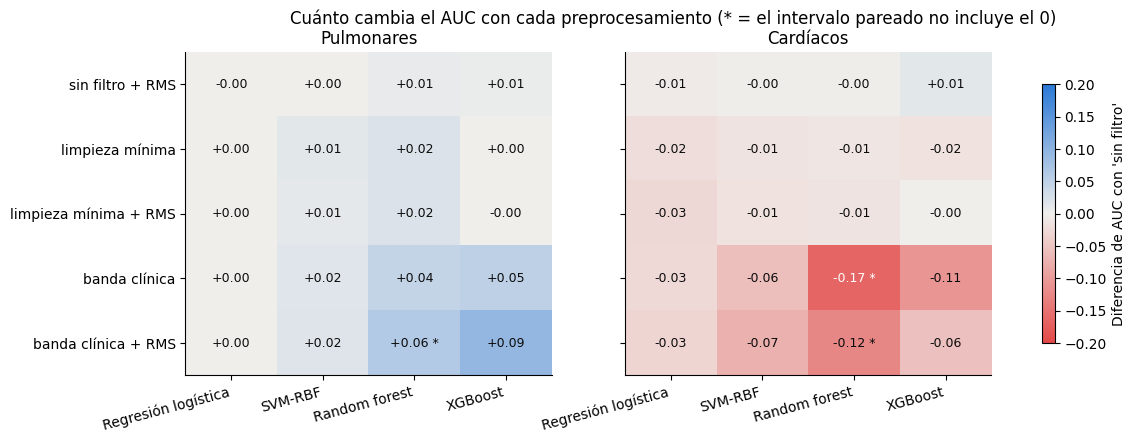

In [5]:
comparaciones = []
for subset in META:
    y = datos(subset, BASE)[1]
    for version in list(candidatos(subset))[1:]:
        for nombre in MODELOS:
            d, (bajo, alto) = dif_pareada(y, probs[(subset, version, nombre)], probs[(subset, BASE, nombre)])
            comparaciones.append({"subconjunto": NOMBRE[subset], "versión": version, "modelo": nombre,
                                  "diferencia": d, "IC 95 %": f"{bajo:+.3f} a {alto:+.3f}",
                                  "real": bajo > 0 or alto < 0})
comparaciones = pd.DataFrame(comparaciones)

MAPA_DIF = LinearSegmentedColormap.from_list("dif", ["#e34948", "#f0efec", AZUL])   # rojo empeora · gris = igual · azul mejora
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, subset in zip(axes, META):
    t = comparaciones[comparaciones.subconjunto == NOMBRE[subset]]
    valores = t.pivot(index="versión", columns="modelo", values="diferencia").loc[list(candidatos(subset))[1:], MODELOS]
    reales = t.pivot(index="versión", columns="modelo", values="real").loc[valores.index, MODELOS]
    imagen = ax.imshow(valores.values, cmap=MAPA_DIF, norm=TwoSlopeNorm(vmin=-0.2, vcenter=0, vmax=0.2), aspect="auto")
    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):
            v = valores.values[i, j]
            ax.text(j, i, f"{v:+.2f}{' *' if reales.values[i, j] else ''}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > 0.14 else TINTA)
    ax.set(xticks=range(len(MODELOS)), yticks=range(valores.shape[0]), title=NOMBRE[subset])
    ax.set_xticklabels(MODELOS, rotation=15, ha="right")
    ax.set_yticklabels(valores.index)
    ax.grid(False)
fig.colorbar(imagen, ax=axes, label="Diferencia de AUC con 'sin filtro'", shrink=0.8)
fig.suptitle("Cuánto cambia el AUC con cada preprocesamiento (* = el intervalo pareado no incluye el 0)")

print(comparaciones[comparaciones.real].round(3).to_string(index=False))

**Cómo leerlo.** Hicimos **40 comparaciones** (5 versiones × 4 modelos × 2
subconjuntos). Con un criterio del 95 %, aunque ningún filtro hiciera nada,
esperaríamos que unas 2 salieran "reales" por azar (notebook 11, sección 5).
Por eso no conviene leer cada asterisco por separado, sino buscar **patrones
que se repitan en los cuatro modelos**:

- **Pulmonares, banda clínica (100–1000 Hz):** los cuatro modelos mejoran o
  quedan igual. La regresión logística no puede mejorar (ya estaba en 1,00),
  pero los modelos de árboles mejoran bastante (random forest de 0,93 a 0,99,
  XGBoost de 0,87 a 0,96 con la normalización). La única diferencia
  pulmonar con asterisco es de esta fila (el random forest con
  normalización).
- **Cardíacos, banda clínica (25–400 Hz):** los cuatro modelos **empeoran**,
  el random forest con un asterisco en las dos versiones (de 0,82 a 0,66 sin
  normalizar). Es el resultado más claro de la notebook, y va **en contra** de
  lo que esperábamos.
- **Limpieza mínima y normalización sola:** cambios chicos (en cardíacos, la
  limpieza mínima baja un poco a los cuatro modelos, entre 0,01 y 0,03),
  ninguno distinguible del azar.

Solo 3 de las 40 comparaciones tienen asterisco, cerca de las ~2 que
esperaríamos por azar. Por eso pesa más que los patrones se repitan en los
cuatro modelos que cada asterisco por separado.

En la especificidad: en pulmonares, la banda clínica o la normalización
suben la de la regresión logística (de 0,86 a 0,97–1,00); en cardíacos, el
random forest sigue sin reconocer normales con el umbral 0,5 con cualquier
preprocesamiento (eso es la notebook 14).

## 4. ¿Por qué la banda clínica empeora la clasificación cardíaca?

Miramos **dónde está la diferencia** entre normales y patológicos en el
espectro. Para cada grabación calculamos su espectro (con la señal
normalizada, para comparar la forma y no el volumen) y promediamos por clase.
La zona sombreada es la banda clínica de cada subconjunto.

¿Cuánto separa la fracción de energía de cada banda, sola? (max(AUC, 1 − AUC))
            25–100 Hz  100–200 Hz  200–400 Hz  400–600 Hz  600–1000 Hz  1000–1500 Hz  1500–2000 Hz
Cardíacos        0.70        0.70        0.64        0.70          0.8          0.71          0.56
Pulmonares       0.51        0.71        0.78        0.67          0.7          0.59          0.75


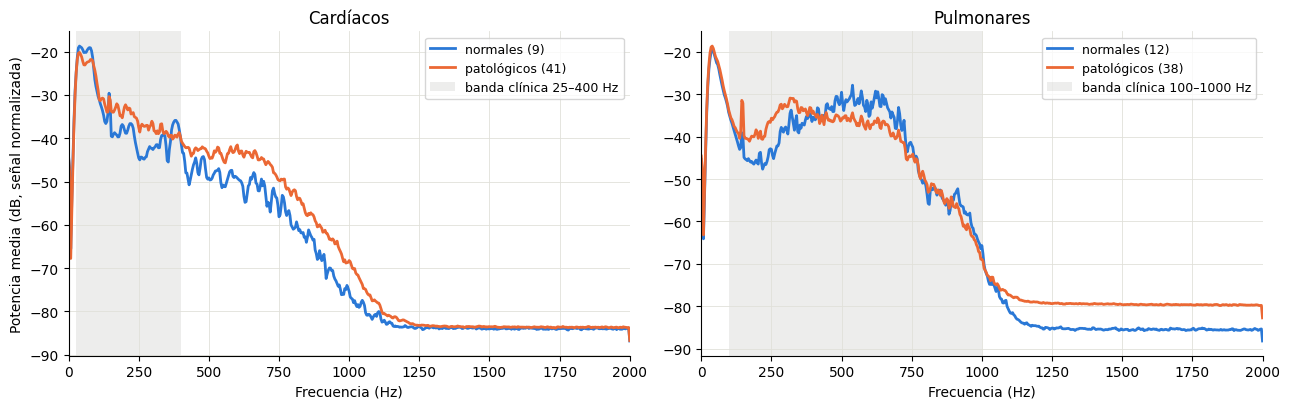

In [6]:
def espectro_db(y):
    f, p = signal.welch(y / rms(y), fs=SR, nperseg=1024)
    return f, 10 * np.log10(p + 1e-20)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, subset in zip(axes, ["HS", "LS"]):
    meta, col_id, _ = META[subset]
    for clase, color, etiqueta in [(0, AZUL, "normales"), (1, NARANJA, "patológicos")]:
        espectros = [espectro_db(audios[subset][fid])[1] for fid in meta.loc[meta["binary_label"] == clase, col_id]]
        f = espectro_db(audios[subset][meta[col_id].iloc[0]])[0]
        ax.plot(f, np.mean(espectros, axis=0), color=color, lw=2, label=f"{etiqueta} ({len(espectros)})")
    ax.axvspan(*BANDA_CLINICA[subset], color=GRIS, alpha=0.15, lw=0, label=f"banda clínica {BANDA_CLINICA[subset][0]}–{BANDA_CLINICA[subset][1]} Hz")
    ax.set(xlim=(0, 2000), xlabel="Frecuencia (Hz)", title=NOMBRE[subset])
    ax.legend(fontsize=9)
axes[0].set_ylabel("Potencia media (dB, señal normalizada)")
fig.tight_layout()

BANDAS = [(25, 100), (100, 200), (200, 400), (400, 600), (600, 1000), (1000, 1500), (1500, 2000)]
filas = {}
for subset in ["HS", "LS"]:
    meta, col_id, _ = META[subset]
    fracciones = []
    for fid in meta[col_id]:
        f, p = signal.welch(audios[subset][fid], fs=SR, nperseg=1024)
        fracciones.append({f"{a}–{b} Hz": p[(f >= a) & (f < b)].sum() / p.sum() for a, b in BANDAS})
    fracciones = pd.DataFrame(fracciones)
    y = meta["binary_label"].values
    filas[NOMBRE[subset]] = {c: max(roc_auc_score(y, fracciones[c]), 1 - roc_auc_score(y, fracciones[c]))
                             for c in fracciones}
print("¿Cuánto separa la fracción de energía de cada banda, sola? (max(AUC, 1 − AUC))")
print(pd.DataFrame(filas).T.round(2).to_string())

**En cardíacos**, los patológicos tienen **más energía entre 400 y 1000 Hz**
que los normales (en el gráfico, la curva naranja se separa de la azul a la
derecha de la banda sombreada), y la fracción de energía entre 600 y 1000 Hz
es la que más separa sola (0,80). El pasa banda de 25–400 Hz borra justo esa
zona. Es lo que temíamos en la notebook 01: los soplos agregan sonido de
espectro ancho, que llega a varios cientos de Hz.

**La lección:** el 25–400 Hz es una banda pensada para **segmentar** (encontrar
R1 y R2, que son graves), no para **clasificar**. Un filtro bueno para una
tarea no es necesariamente bueno para otra.

**En pulmonares**, la diferencia está repartida: los patológicos tienen más
energía entre 100 y 400 Hz (donde viven los ruidos agregados) y también por
encima de 1000 Hz. La banda clínica deja la primera y saca la segunda. Que el
resultado no empeore, y que los árboles mejoren, sugiere que lo que había por
encima de 1000 Hz no era imprescindible (y la notebook 02 mostró que esa zona
tiene el siseo del equipo).

Un detalle del gráfico: por encima de ~1100 Hz las dos curvas son **planas**.
No es sonido respiratorio, es el **piso de ruido** del equipo. En pulmonares,
ese piso está más alto en los patológicos (cerca de −79 dB contra −85 dB):
una diferencia de **condición de grabación**, como la de la notebook 05, que
un modelo podría aprovechar sin escuchar nada clínico. La banda clínica la
saca (sección 6).

Por tipo de patología, en cardíacos:

In [7]:
def auc_por_tipo(subset, version, nombres=MODELOS):
    X, y, caso, tipo = datos(subset, version)
    normales = tipo == "Normal"
    tipos = pd.Series(tipo[~normales]).value_counts().index
    return pd.DataFrame({n: {f"{t} ({(tipo == t).sum()})": auc_medio(
        np.r_[np.zeros(normales.sum()), np.ones((tipo == t).sum())],
        [np.r_[p[normales], p[tipo == t]] for p in probs[(subset, version, n)]]) for t in tipos} for n in nombres})


por_tipo = pd.concat({v: auc_por_tipo("HS", v, ["Regresión logística", "Random forest"])
                      for v in [BASE, "banda clínica"]}, axis=1)
print(por_tipo.round(2).to_string())

                                   sin filtro                     banda clínica              
                          Regresión logística Random forest Regresión logística Random forest
Mid Systolic Murmur (7)                  0.74          0.69                0.75          0.65
Late Diastolic Murmur (6)                0.90          0.99                0.85          0.86
Early Systolic Murmur (6)                0.91          0.94                0.81          0.56
S3 (5)                                   0.87          0.85                0.88          0.71
Late Systolic Murmur (5)                 0.90          0.98                0.92          0.79
Atrial Fibrillation (4)                  0.70          0.69                0.64          0.48
Tachycardia (3)                          0.86          0.72                0.83          0.57
AV Block (3)                             0.68          0.57                0.68          0.52
S4 (2)                                   0.80          0.78 

Pierden sobre todo los **soplos** (con el random forest, el sistólico precoz
cae de 0,94 a 0,56 y el sistólico tardío de 0,98 a 0,79), y también el R3, el
R4 y la fibrilación auricular. La regresión logística pierde menos: baja en
el sistólico precoz (de 0,91 a 0,81) y algo en el diastólico tardío y la
fibrilación auricular, y en el resto queda prácticamente igual.

## 5. El pasa bajo, corte por corte (cardíacos)

Tu directora preguntó por un **pasa bajo** para los sonidos cardíacos, y en la
notebook 01 anotamos probar varios cortes. Lo hacemos con un barrido: pasa
bajo en 100, 200, 300, 400, 600, 800 y 1000 Hz, y sin filtro (que equivale a
cortar en 2000 Hz, el límite de la grabación).

**Esto no es para elegir el corte.** Si eligiéramos el que mejor da, sería
elegir mirando los resultados. Es una **curva de sensibilidad**: sirve para
entender **hasta dónde llega la información** útil. *(Tarda unos 2 minutos.)*

(101 segundos)
                      100    200    300    400    600    800    1000   2000
Regresión logística  0.568  0.640  0.812  0.763  0.831  0.806  0.812  0.827
SVM-RBF              0.442  0.664  0.758  0.726  0.836  0.806  0.808  0.833
Random forest        0.626  0.583  0.715  0.701  0.818  0.821  0.799  0.823
XGBoost              0.621  0.553  0.658  0.735  0.847  0.737  0.742  0.752


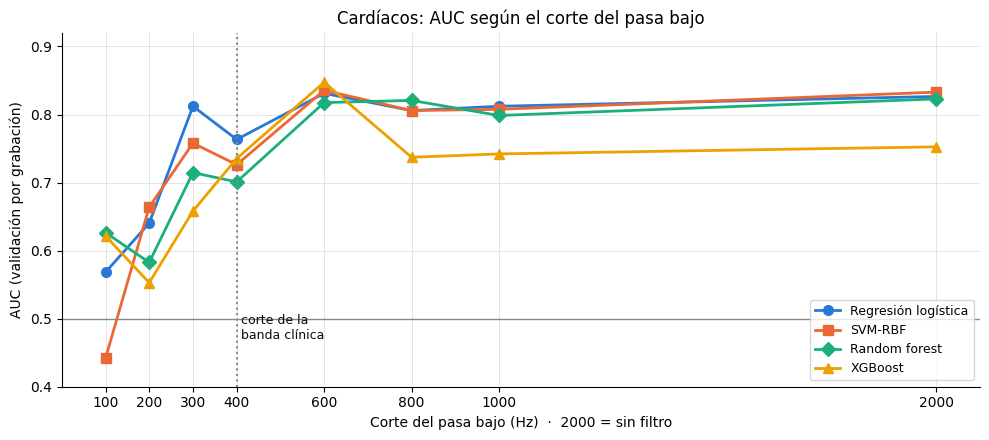

In [8]:
CORTES = [100, 200, 300, 400, 600, 800, 1000]
meta, col_id, _ = META["HS"]
y_hs = meta["binary_label"].values
barrido = {}
inicio = time.time()
for corte in CORTES:
    X = pd.DataFrame([extraer(preprocesar(audios["HS"][fid], pasa_bajo=corte)) for fid in meta[col_id]])
    barrido[corte] = {n: auc_medio(y_hs, prob_validacion(m, X, y_hs)) for n, m in modelos(y_hs).items()}
barrido[2000] = {n: auc_medio(y_hs, probs[("HS", BASE, n)]) for n in MODELOS}   # sin filtro
barrido = pd.DataFrame(barrido)
print(f"({time.time() - inicio:.0f} segundos)")
print(barrido.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
for (nombre, fila), color, marca in zip(barrido.iterrows(), [AZUL, NARANJA, AQUA, AMARILLO], ["o", "s", "D", "^"]):
    ax.plot(fila.index, fila.values, marker=marca, color=color, lw=2, ms=7, label=nombre)
ax.axvline(400, color=GRIS, ls=":", lw=1.5)
ax.text(410, 0.47, "corte de la\nbanda clínica", fontsize=9, color=TINTA)
ax.axhline(0.5, color=GRIS, lw=1)
ax.set(xlim=(0, 2100), ylim=(0.4, 0.92), xlabel="Corte del pasa bajo (Hz)  ·  2000 = sin filtro",
       ylabel="AUC (validación por grabación)", title="Cardíacos: AUC según el corte del pasa bajo")
ax.set_xticks([100, 200, 300, 400, 600, 800, 1000, 2000])
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

**Cómo leerlo:**
- Con cortes **bajos** (100–200 Hz), todos los modelos quedan cerca del azar
  (0,44 a 0,66): lo que hay debajo de 200 Hz (R1, R2 y los ruidos graves) no
  alcanza para distinguir.
- Entre 200 y 600 Hz el AUC **sube**: ahí entra la información de los soplos.
- Desde **600 Hz** en adelante la curva queda **plana**, al nivel de no
  filtrar: lo que está por encima de ~600 Hz ya no agrega (ni quita). La
  excepción es XGBoost, que salta de 0,85 a 0,74: es tan frágil como vimos
  en la notebook 11.
- La curva no es suave (por ejemplo, 300 Hz da mejor que 400 en algunos
  modelos): con 50 grabaciones, cada punto tiene mucho ruido. Lo que importa es
  la forma general.

**Para la tesis:** un pasa bajo para los sonidos cardíacos **no debería
cortar por debajo de ~600 Hz**; por debajo borra información de los soplos. Y
no filtrar da lo mismo que cortar en 600 o más: en estas grabaciones, el
filtro no aporta.

## 6. ¿El resultado pulmonar depende del volumen?

En la notebook 02 vimos que, en pulmonares, el **volumen solo** ya distingue
bastante, y en la 05, que normalizar no borraba del todo esa pista: algunas
features de forma seguían asociadas al volumen original (una "condición de
grabación"). Ahora lo medimos con la extracción corregida:
1. ¿Cuánto separa el volumen solo?
2. ¿Cuántas features quedan muy asociadas al volumen original (|correlación
   de Spearman| > 0,8) en cada versión?
3. ¿Cae el AUC al normalizar?

In [9]:
for subset in META:
    meta, col_id, _ = META[subset]
    volumen = np.array([rms(audios[subset][fid]) for fid in meta[col_id]])
    y = meta["binary_label"].values
    print(f"\n{NOMBRE[subset]}: el volumen solo (RMS original) separa "
          f"{max(roc_auc_score(y, volumen), 1 - roc_auc_score(y, volumen)):.2f}")
    filas = []
    for version in candidatos(subset):
        X = datos(subset, version)[0]
        corr = X.apply(lambda c: abs(pd.Series(c.values).corr(pd.Series(volumen), method="spearman")))
        filas.append({"versión": version, "features con |r| > 0,8": int((corr > 0.8).sum()),
                      "la más asociada": f"{corr.idxmax()} ({corr.max():.2f})",
                      "AUC regresión logística": auc_medio(y, probs[(subset, version, "Regresión logística")])})
    print(pd.DataFrame(filas).round(3).to_string(index=False))


Pulmonares: el volumen solo (RMS original) separa 0.78


              versión  features con |r| > 0,8   la más asociada  AUC regresión logística
           sin filtro                       8   rms_mean (0.98)                    0.999
     sin filtro + RMS                       4 mfcc_1_min (0.91)                    0.999
      limpieza mínima                       7   rms_mean (0.98)                    0.999
limpieza mínima + RMS                       2 mfcc_2_min (0.86)                    1.000
        banda clínica                       2 mfcc_1_max (0.80)                    1.000
  banda clínica + RMS                       0 mfcc_3_max (0.80)                    1.000

Cardíacos: el volumen solo (RMS original) separa 0.54


              versión  features con |r| > 0,8   la más asociada  AUC regresión logística
           sin filtro                       2   rms_mean (0.97)                    0.827
     sin filtro + RMS                       1 mfcc_1_min (0.84)                    0.821
      limpieza mínima                       2   rms_mean (0.97)                    0.805
limpieza mínima + RMS                       0 mfcc_4_max (0.78)                    0.799
        banda clínica                       3   rms_mean (0.97)                    0.801
  banda clínica + RMS                       0 mfcc_6_max (0.79)                    0.797


**Cómo leerlo:**
- En **pulmonares**, el volumen solo separa 0,78: es una pista disponible, sin
  sentido clínico (refleja cómo se grabaron los normales en el maniquí). En
  cardíacos no separa (0,54).
- Sin filtrar ni normalizar, 8 features pulmonares siguen al volumen casi al
  pie de la letra. Normalizar solo baja a 4, como vimos en la notebook 05:
  normalizar no alcanza. Con la **banda clínica + normalización**, **ninguna**
  supera 0,8 (la más asociada queda justo en 0,80).
- Y el AUC de la regresión logística **no cae** en ninguna versión: sigue en
  ~1,00.

**Conclusión:** el resultado pulmonar **no depende del volumen**. La
"condición de grabación" de la notebook 05 vivía en buena parte fuera de la
banda de 100–1000 Hz (el siseo, el retumbo), y al sacarla el modelo sigue
distinguiendo igual: se apoya en el sonido respiratorio. Es un argumento
fuerte para la tesis.

## 7. La validación por caso, con el control de pseudo-casos

Repetimos el control para las seis versiones, con la regresión logística y el
SVM-RBF (los modelos de árboles tardarían demasiado, y en la notebook 11 su
fuga ya no era medible con la extracción corregida). *(Tarda alrededor de un
minuto.)*

In [10]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


def auc_por_grupos(modelo, X, y, grupos):
    return roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), grupos))


filas = []
for subset in META:
    for version in candidatos(subset):
        X, y, caso, tipo = datos(subset, version)
        rng = np.random.default_rng(SEMILLA)
        sorteos = [pseudo_casos(caso, y, rng) for _ in range(5)]   # los mismos sorteos para todas las versiones
        for nombre in ["Regresión logística", "SVM-RBF"]:
            modelo = modelos(y)[nombre]
            pseudo = [auc_por_grupos(modelo, X, y, g) for g in sorteos]
            real = auc_por_grupos(modelo, X, y, caso)
            filas.append({"subconjunto": NOMBRE[subset], "versión": version, "modelo": nombre,
                          "pseudo-caso (media)": np.mean(pseudo),
                          "pseudo-caso (mín–máx)": f"{np.min(pseudo):.2f}–{np.max(pseudo):.2f}",
                          "caso real": real, "¿fuga?": "sí" if real < np.min(pseudo) else "no medible"})
print(pd.DataFrame(filas).round(3).to_string(index=False))

subconjunto               versión              modelo  pseudo-caso (media) pseudo-caso (mín–máx)  caso real     ¿fuga?
 Pulmonares            sin filtro Regresión logística                0.989             0.98–1.00      0.956         sí
 Pulmonares            sin filtro             SVM-RBF                0.927             0.89–0.97      0.864         sí
 Pulmonares      sin filtro + RMS Regresión logística                0.984             0.97–0.99      0.939         sí
 Pulmonares      sin filtro + RMS             SVM-RBF                0.919             0.90–0.96      0.871         sí
 Pulmonares       limpieza mínima Regresión logística                0.993             0.99–1.00      0.969         sí
 Pulmonares       limpieza mínima             SVM-RBF                0.944             0.93–0.98      0.893         sí
 Pulmonares limpieza mínima + RMS Regresión logística                0.994             0.98–1.00      0.978         sí
 Pulmonares limpieza mínima + RMS             SV

**Cómo leerlo:**
- **Pulmonares:** sin filtro, la regresión logística y el SVM-RBF tienen una
  fuga chica pero real (el caso real queda por debajo de todos los
  pseudo-casos). Con la **banda clínica + normalización** la fuga deja de ser
  medible, y el AUC validando por caso **sube** (la regresión logística, de
  0,96 a 0,99). Es coherente con la sección 6: lo que quedaba fuera de
  100–1000 Hz era, en parte, una "firma" de la grabación que compartían las
  grabaciones del mismo caso, y el modelo la aprovechaba.
- **Cardíacos:** ninguna versión muestra fuga medible; la banda clínica
  también empeora la validación por caso.

## 8. Qué nos llevamos

1. **Pulmonares: la banda clínica (100–1000 Hz + notch) con normalización
   RMS.** No la elegimos por el AUC (la regresión logística da ~1,00 con
   cualquier versión), sino por lo que buscábamos en la notebook 10: que el
   resultado **no dependa de cosas no fisiológicas**. Con ella, ninguna
   feature queda asociada al volumen, la fuga por caso deja de ser medible y los
   modelos de árboles mejoran. Va a ser importante para la validación externa
   (notebook 16), donde el equipo y el volumen son otros.
2. **Cardíacos: no filtrar.** Ningún candidato mejora, y la banda clínica de
   25–400 Hz empeora, porque borra la energía de los soplos entre 400 y 1000
   Hz. El barrido del pasa bajo muestra que la información llega por lo menos
   hasta ~600 Hz. Normalizar el volumen es indiferente (el volumen no separa).
3. **Para la tesis:** "el filtro estándar para segmentar sonidos cardíacos no
   sirve para clasificarlos" es un resultado concreto, con una explicación
   física, y responde la pregunta de tu directora.
4. Las notebooks 13 (ritmo) y 14 (umbral) siguen comparándose contra la línea
   de base de la 11, para medir cada cambio por separado. La combinación final
   se arma al final.

## 9. Cómo explicárselo a tu directora (en 5 frases)

1. *"Probé tres preprocesamientos fijados de antemano (sin filtro, una
   limpieza mínima de 20–1000 Hz y una banda clínica), cada uno con y sin
   normalización de volumen, con cuatro modelos y un bootstrap pareado contra
   la línea de base."*
2. *"En cardíacos, la banda clínica de 25–400 Hz, la estándar para segmentar,
   empeora la clasificación con los cuatro modelos: los patológicos tienen más
   energía entre 400 y 1000 Hz, y el filtro la borra."*
3. *"Un barrido del pasa bajo muestra que la información útil llega por lo
   menos hasta 600 Hz; por debajo, el AUC cae hasta el azar."*
4. *"En pulmonares, el resultado no depende del volumen: con la banda de
   100–1000 Hz y normalización, ninguna feature sigue al volumen y la regresión
   logística sigue en un AUC de ~1,00."*
5. *"Además, con ese preprocesamiento desaparece la fuga entre grabaciones del
   mismo caso: el modelo pulmonar se apoya en el sonido respiratorio, no en la
   firma de la grabación."*

## 10. Tu turno: escuchar lo que borra el filtro

Elegí una grabación con soplo y escuchala sin filtro y con la banda clínica de
25–400 Hz (con auriculares se nota más). Abajo están los dos espectrogramas:
¿qué desaparece? ¿Lo reconocerías igual como soplo?

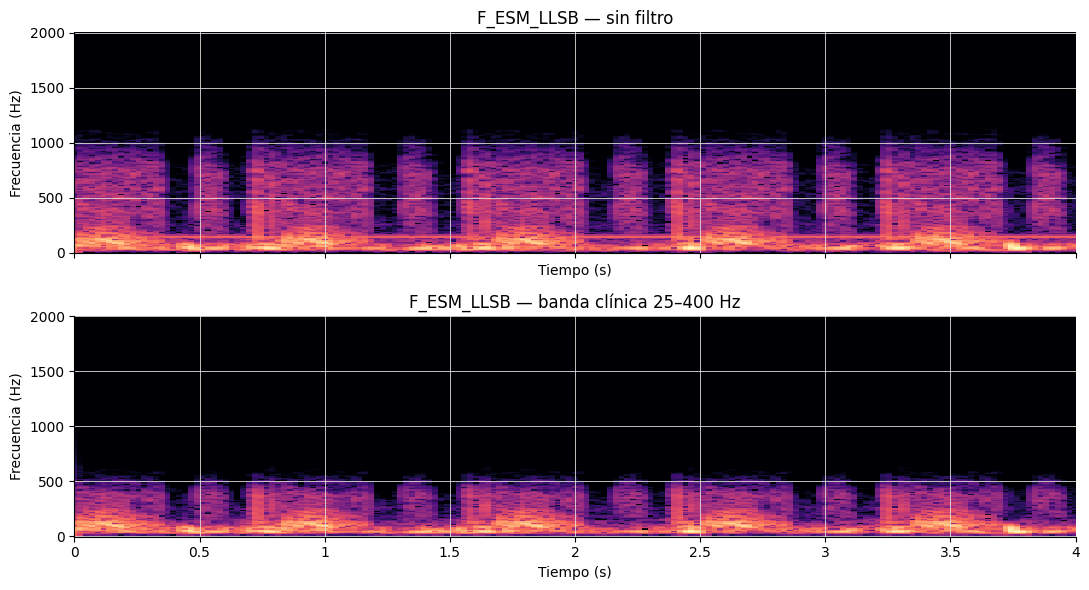

In [11]:
GRABACION = "F_ESM_LLSB"   # un soplo sistólico precoz; probá con otras (por ejemplo, de la tabla de la sección 4)

y = audios["HS"][GRABACION]
filtrada = preprocesar(y, banda=BANDA_CLINICA["HS"], notch=True)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
referencia = np.max(np.abs(librosa.stft(y, n_fft=372, hop_length=93)))
for ax, (titulo, senal) in zip(axes, [("sin filtro", y), ("banda clínica 25–400 Hz", filtrada)]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(senal, n_fft=372, hop_length=93)), ref=referencia)
    librosa.display.specshow(S, sr=SR, hop_length=93, x_axis="time", y_axis="hz", ax=ax, vmin=-70, vmax=0)
    ax.set(title=f"{GRABACION} — {titulo}", xlim=(0, 4), xlabel="Tiempo (s)", ylabel="Frecuencia (Hz)")
    display(Audio(senal, rate=SR))
fig.tight_layout()

**Lo que se ve:** sin filtro, el soplo es la mancha que llena el espacio
entre R1 y R2 y llega hasta ~1000 Hz. Con la banda de 25–400 Hz queda solo la
parte de abajo (hasta ~500 Hz, por la caída gradual del filtro): el soplo se
sigue viendo, pero recortado, y debería sonar más apagado, como a través de
una pared. El modelo pierde lo mismo que el oído: la parte aguda del soplo,
la que más lo distingue de un normal.

## Preguntas de control

1. ¿Cuáles son los tres filtros candidatos y por qué se fijaron antes de ver
   los resultados?
2. ¿Por qué normalizamos por RMS y no por el pico?
3. Hicimos 40 comparaciones. ¿Cuántas esperarías que salieran "reales" por
   azar? ¿Cómo conviene leer el resultado entonces?
4. ¿Por qué la banda de 25–400 Hz empeora la clasificación cardíaca, si es la
   estándar para sonidos cardíacos?
5. ¿Qué es una curva de sensibilidad? ¿Qué muestra el barrido del pasa bajo, y
   por qué no lo usamos para elegir el corte?
6. ¿El resultado pulmonar depende del volumen? ¿Cómo lo sabemos?
7. ¿Qué pasa con la fuga por caso en pulmonares con la banda clínica y la
   normalización? ¿Cómo se relaciona con la "condición de grabación"?
8. ¿Qué preprocesamiento recomendarías para cada subconjunto, y con qué
   argumento?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** Sin filtro (la referencia), limpieza mínima (20–1000 Hz + notch en 146
Hz: saca solo lo no fisiológico) y banda clínica (cardíacos 25–400 Hz,
pulmonares 100–1000 Hz, + notch). Se fijaron antes porque elegir el filtro
mirando el AUC sería ajustar el preprocesamiento a las mismas grabaciones con
las que evaluamos (una fuga), y entre muchos filtros alguno ganaría por azar.

**2.** Porque el pico depende de una sola muestra (un golpe o un roce lo
cambia todo), mientras que el RMS resume la energía de toda la grabación.

**3.** Con un criterio del 95 %, un 5 % de 40: unas 2. Por eso no conviene
leer cada asterisco aislado, sino buscar patrones que se repitan en los
cuatro modelos: por ejemplo, que la banda clínica cardíaca empeore a todos.

**4.** Porque es una banda pensada para segmentar (encontrar R1 y R2, que son
graves), no para clasificar. Los soplos agregan energía entre 400 y 1000 Hz,
justo donde los patológicos se diferencian más de los normales, y el filtro la
borra.

**5.** Es medir el resultado al variar un parámetro, para ver cuánto depende
de él. El barrido muestra que el AUC cardíaco cae con cortes por debajo de
~600 Hz y queda plano por encima: la información útil llega por lo menos hasta
600 Hz. No lo usamos para elegir porque elegir el mejor corte mirando el AUC
sería optimista (y con 50 grabaciones, la curva tiene mucho ruido).

**6.** No. El volumen solo separa bastante (0,78), pero al normalizar el AUC
no cae; y con la banda clínica + normalización ninguna feature queda
asociada al volumen original, y la regresión logística sigue en ~1,00.

**7.** La fuga deja de ser medible y el AUC por caso sube. Parte de la
"condición de grabación" (siseo, retumbo) estaba fuera de 100–1000 Hz y la
compartían las grabaciones del mismo caso: al sacarla, el modelo ya no puede
reconocer la "firma" de la grabación hermana.

**8.** Pulmonares: banda clínica (100–1000 Hz + notch) con normalización RMS,
porque hace al resultado independiente del volumen y de la firma de la
grabación, sin perder desempeño (y eso importa para la validación externa).
Cardíacos: no filtrar, porque ningún candidato mejora y la banda clínica
empeora; normalizar es indiferente.